# Упражнения по Boosting and Stacking 

![Boosting.png](../asets/Boosting.png)

# Цели обучения

- Объяснить, как алгоритм бустинга помогает снизить дисперсию и систематическую ошибку.

## Введение

Мы будем использовать базу данных [«Распознавание действий человека с помощью смартфонов»](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), сформированную на основе записей участников исследования, выполнявших повседневные действия (ADL) с смартфоном, оснащенным встроенными инерционными датчиками. Цель состоит в классификации действий по одному из шести видов (ходьба, подъем по лестнице, спуск по лестнице, сидение, стояние и лежание).

Для каждой записи в наборе данных предоставляются следующие данные:

- Трехосное ускорение, полученное с акселерометра (общее ускорение), и расчетное ускорение тела.
- Трехосевая угловая скорость, полученная с гироскопа.
- Вектор из 561 признака с переменными во временной и частотной областях.
- Метка вида деятельности.

Более подробная информация о признаках доступна на указанном выше веб-сайте.

In [1]:
from __future__ import print_function
import os
import time
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import VotingClassifier

from sklearnex import patch_sklearn
patch_sklearn()

%matplotlib inline
sns.set_style('whitegrid')
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные из файла `Human_Activity_Recognition_Using_Smartphones_Data.csv` и проанализируйте структуру и типы данных. Типов данных будет слишком много, чтобы перечислять их по каждому столбцу отдельно. Вместо этого сгруппируйте типы по количеству.
* Определите, требуется ли масштабирование столбцов с числами типа float.

In [2]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)

(10299, 562)


В наборе данных довольно много столбцов с предикторами.

In [3]:
data.dtypes.value_counts()

float64    561
str          1
Name: count, dtype: int64

И все они — значения типа float. Единственное значение, не относящееся к типу float, — это столбец «categories», который и является объектом прогнозирования.

In [4]:
data.dtypes.tail()

angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
dtype: object

Минимальное и максимальное значения для столбцов типа float составляют -1,0 и 1,0 соответственно. Однако для методов, основанных на дереве, масштабирование никогда не требуется.

In [5]:
print('минимумы признаков:', data.iloc[:, :-1].min().value_counts().to_dict())
print('максимумы признаков:', data.iloc[:, :-1].max().value_counts().to_dict())

минимумы признаков: {-1.0: 561}
максимумы признаков: {1.0: 561}


**Ответ.**

10299 записей и 562 столбца: 561 признак типа `float64` и столбец `Activity` (строка), его и нужно предсказать. У всех признаков минимум -1 и максимум 1, то есть данные уже нормированы.

Масштабирование не нужно: для деревьев оно вообще не важно, а для логистической регрессии в вопросе 6 признаки и так в одном диапазоне.

## Вопрос 2

* Присвойте действиям целочисленные коды.
* Разделите данные на обучающий и тестовый наборы. Решите, будет ли производиться стратификация данных при разделении на обучающий и тестовый наборы или нет.

**ПРИМЕЧАНИЕ**: Мы собираемся создать обучающий и тестовый наборы данных из `data`. На этих наборах данных мы будем проводить поиск по сетке с различными значениями параметров. Это может занять некоторое время. Чтобы сократить время поиска по сетке, вы можете уменьшить разрешение `data` и создать `X_train, X_test, y_train, y_test` на основе набора данных с уменьшенным разрешением.

Теперь разделите данные на обучающий и тестовый наборы. Здесь не использовалось стратифицированное деление. Если возникнут проблемы с какими-либо метриками ошибок на тестовом наборе, может быть целесообразно начать подбор модели с использованием стратифицированного деления. Однако метод бустинга является довольно мощной моделью, поэтому в данном случае это может оказаться ненужным.

In [6]:
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])
print(dict(enumerate(le.classes_)))

feature_columns = [x for x in data.columns if x != 'Activity']

# все-таки делаю стратифицированное разбиение, чтобы доли классов в train и test совпадали
X_train, X_test, y_train, y_test = train_test_split(data[feature_columns], data['Activity'],
                                                    test_size=0.3, random_state=42, stratify=data['Activity'])
print('train:', X_train.shape, ' test:', X_test.shape)
pd.DataFrame({'train': y_train.value_counts(normalize=True), 'test': y_test.value_counts(normalize=True)})\
  .rename(index=dict(enumerate(le.classes_))).round(4)

{0: 'LAYING', 1: 'SITTING', 2: 'STANDING', 3: 'WALKING', 4: 'WALKING_DOWNSTAIRS', 5: 'WALKING_UPSTAIRS'}
train: (7209, 561)  test: (3090, 561)


,train,test
Activity,,
LAYING,0.1888,0.1887
STANDING,0.1850,0.1851
SITTING,0.1726,0.1725
WALKING,0.1672,0.1673
WALKING_UPSTAIRS,0.1500,0.1498
WALKING_DOWNSTAIRS,0.1365,0.1366


**Ответ.**

Коды классов: 0 - LAYING, 1 - SITTING, 2 - STANDING, 3 - WALKING, 4 - WALKING_DOWNSTAIRS, 5 - WALKING_UPSTAIRS.

Разбиение 70/30, со стратификацией: хуже от нее не будет, а доли классов в train и test получаются одинаковыми. `random_state=42` такой же, как в лабе 5, поэтому результаты можно сравнивать с ней.

Уменьшать данные не пришлось, каждый поиск по сетке ниже занял около полутора минут.

## Вопрос 3

* Постройте модели градиентного бустинга с деревьями, установив все параметры по умолчанию, для следующих значений количества деревьев (`n_estimators = [25, 50, 100, 200, 400]`) и оцените точность на тестовых данных для каждой из этих моделей.
* Постройте график зависимости точности от количества оценок.

**Примечание:** Выполнение этого задания может занять некоторое время в зависимости от количества различных значений, подбираемых для оценок. Установка параметра `max_features=4` в классификаторе градиентного бустинга увеличит скорость сходимости.

Кроме того, это задание аналогично заданию 3 из 9-й недели, за исключением того, что для моделей с бустингом не существует такого понятия, как «ошибка out-of-bag». Кроме того, в модели градиентного бустинга присутствует ошибка в настройке `warm_flag=True`, поэтому не используйте её. Просто создайте модель внутри цикла `for` и задайте количество оценок в этот момент. Это приведёт к тому, что подбор модели займёт немного больше времени. Кроме того, подбор моделей бустинга, как правило, занимает больше времени, чем подбор моделей методом bagging, поскольку «решающие пеньки» необходимо подбирать последовательно.

In [7]:
error_list = list()

# Iterate through various possibilities for number of trees
tree_list = [25, 50, 100, 200, 400]
for n_trees in tree_list:

    # Initialize the gradient boost classifier
    GBC = GradientBoostingClassifier(n_estimators=n_trees, max_features=4, random_state=42)

    # Fit the model
    t0 = time.time()
    GBC.fit(X_train.values, y_train.values)
    y_pred = GBC.predict(X_test.values)

    # Get the error
    error = 1.0 - accuracy_score(y_test, y_pred)

    # Store it
    error_list.append(pd.Series({'n_trees': n_trees, 'error': error,
                                 'train error': 1.0 - GBC.score(X_train.values, y_train.values),
                                 'время, с': time.time() - t0}))

error_df = pd.concat(error_list, axis=1).T.set_index('n_trees')

error_df.round(4)

,error,train error,"время, с"
n_trees,,,
25.0,0.0676,0.0513,1.1816
50.0,0.0417,0.0216,2.1303
100.0,0.0207,0.0049,4.2096
200.0,0.0120,0.0001,8.7360
400.0,0.0084,0.0000,17.7294


Теперь построим график результата.

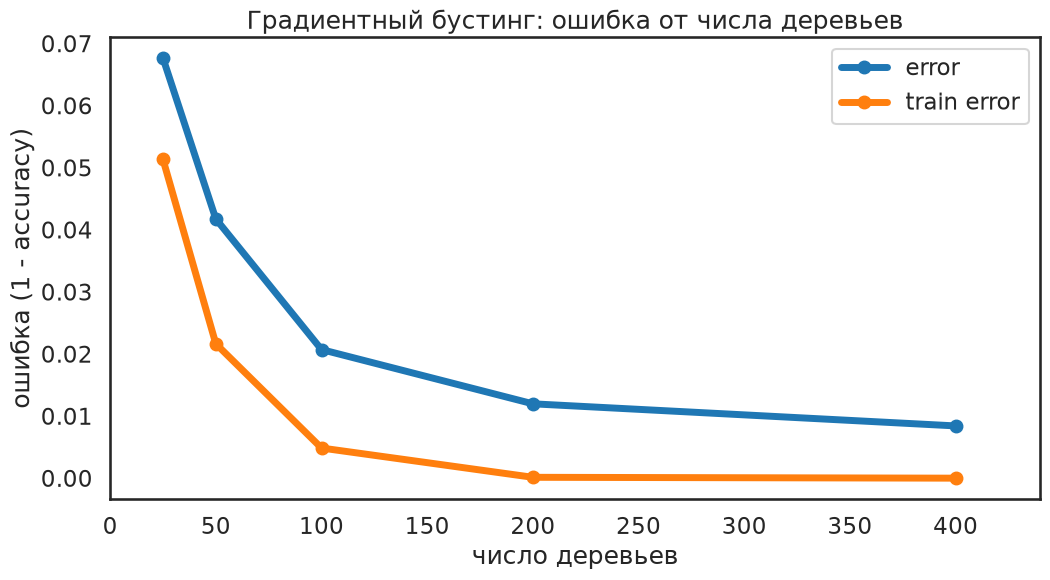

In [8]:
sns.set_context('talk')
sns.set_style('white')

# Create the plot
ax = error_df[['error', 'train error']].plot(marker='o', figsize=(12, 6), linewidth=5)

# Set parameters
ax.set(xlabel='число деревьев', ylabel='ошибка (1 - accuracy)', title='Градиентный бустинг: ошибка от числа деревьев')
ax.set_xlim(0, max(error_df.index)*1.1);

**Ответ.**

Ошибка на test уменьшается с ростом числа деревьев: 6.8% при 25 деревьях, 2.1% при 100 и 0.84% при 400. Ошибка на train при 200 деревьях уже почти нулевая, но на test продолжает падать, так что переобучения пока не видно.

Каждое дерево с `max_features=4` слабое, но в бустинге деревья строятся последовательно, и каждое следующее исправляет ошибки предыдущих, поэтому вместе они дают хороший результат. Время обучения растет примерно линейно с числом деревьев.

## Вопрос 4

* Используя поиск по сетке с перекрестной валидацией, постройте новый классификатор с градиентным бустингом, используя список оценок, аналогично вопросу 3. Также рассмотрите возможность изменения скоростей обучения (0,1; 0,01; 0,001 и т. д.), значения подвыборки (1,0 или 0,5) и количества максимальных признаков (1, 2 и т. д.).
* Проанализируйте параметры модели с наилучшей подгонкой.
* Рассчитайте соответствующие метрики ошибок для этой модели и проанализируйте матрицу путаницы.

**Примечание:** выполнение этого вопроса может занять некоторое время в зависимости от количества признаков, используемых в поиске по сетке. Рекомендуется начать с небольшого количества, чтобы убедиться в корректной работе, а затем добавить больше признаков. Установка параметра `max_features=4` в классификаторе с градиентным бустингом увеличит скорость сходимости.

In [9]:
# The parameters to be fit
param_grid = {'n_estimators': [100, 200, 400],
              'learning_rate': [0.1, 0.01],
              'subsample': [1.0, 0.5],
              'max_features': [2, 4]}

# The grid search object
GV_GBC = GridSearchCV(GradientBoostingClassifier(random_state=42),
                      param_grid=param_grid,
                      scoring='accuracy',
                      cv=cv3,
                      n_jobs=8)

# Do the grid search
t0 = time.time()
GV_GBC = GV_GBC.fit(X_train, y_train)
print(f'{len(GV_GBC.cv_results_["params"])} комбинаций x 3 фолда за {time.time() - t0:.0f} с')

24 комбинаций x 3 фолда за 85 с


In [10]:
# The best model
print(GV_GBC.best_params_, f'accuracy CV: {GV_GBC.best_score_:.4f}')
GV_GBC.best_estimator_

{'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 400, 'subsample': 1.0} accuracy CV: 0.9840


,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",400
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_features max_features: {'sqrt', 'log2'}, int or float, default=NoneThe number of features to consider when looking for the best split:- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0]` and the features considered at each split will be `max(1, int(max_features * n_features_in_))`.- If 'sqrt', then `max_features=sqrt(n_features)`.- If 'log2', then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Choosing `max_features < n_features` leads to a reduction of varianceand an increase in bias.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",4
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Valu

In [11]:
gbc_res = pd.DataFrame(GV_GBC.cv_results_)
gbc_res.pivot_table(index=['param_learning_rate', 'param_n_estimators'],
                    columns=['param_max_features', 'param_subsample'],
                    values='mean_test_score').round(4)

param_max_features                           2               4        
param_subsample                            0.5     1.0     0.5     1.0
param_learning_rate param_n_estimators                                
0.01                100                 0.8691  0.8625  0.8969  0.8972
                    200                 0.8986  0.8925  0.9230  0.9220
                    400                 0.9345  0.9352  0.9510  0.9492
0.10                100                 0.9639  0.9606  0.9692  0.9699
                    200                 0.9742  0.9738  0.9803  0.9789
                    400                 0.9809  0.9809  0.9835  0.9840

Показатели ошибок. Отчет о классификации особенно удобен в случаях с несколькими классами.

In [12]:
y_pred = GV_GBC.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       583
           SITTING     0.9794    0.9794    0.9794       533
          STANDING     0.9825    0.9808    0.9816       572
           WALKING     1.0000    0.9981    0.9990       517
WALKING_DOWNSTAIRS     0.9953    0.9953    0.9953       422
  WALKING_UPSTAIRS     0.9935    0.9978    0.9957       463

          accuracy                         0.9916      3090
         macro avg     0.9918    0.9919    0.9918      3090
      weighted avg     0.9916    0.9916    0.9916      3090



Матрица путаницы. Обратите внимание, что модель с градиентным бустингом испытывает небольшие затруднения при различении классов активности 1 и 2.

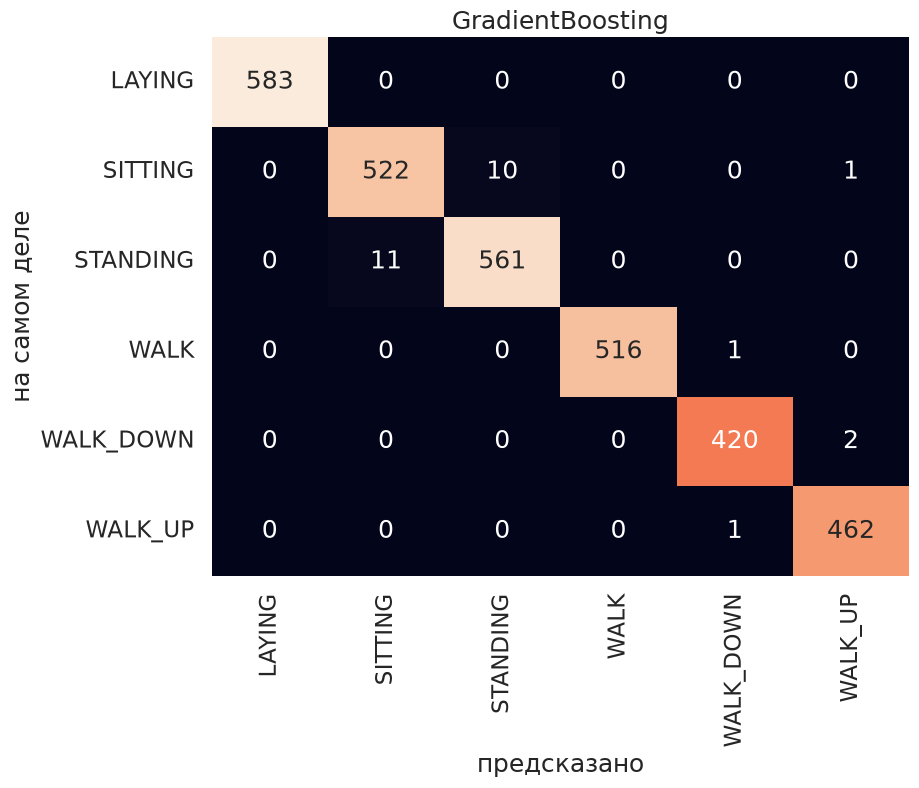

In [13]:
short = ['LAYING', 'SITTING', 'STANDING', 'WALK', 'WALK_DOWN', 'WALK_UP']

sns.set_context('talk')
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, xticklabels=short, yticklabels=short, ax=ax)
ax.set(xlabel='предсказано', ylabel='на самом деле', title='GradientBoosting');

**Ответ.**

Сетка: `n_estimators` = 100, 200, 400, `learning_rate` = 0.1, 0.01, `subsample` = 1.0, 0.5, `max_features` = 2, 4 (24 комбинации, 3 фолда).

Лучшая модель: `learning_rate=0.1`, `n_estimators=400`, `max_features=4`, `subsample=1.0`, accuracy на кросс-валидации 0.984. Число деревьев и `max_features` оказались на границе сетки, так что с большими значениями, возможно, было бы еще лучше, но и обучение было бы дольше.

По сводной таблице видно, что с `learning_rate = 0.01` результаты сильно хуже: с таким маленьким шагом 400 деревьев просто не хватает. `max_features = 4` везде лучше, чем 2, а `subsample` почти ни на что не влияет.

На test accuracy 0.9916, 26 ошибок из 3090. Как и в лабе 5, почти все ошибки - это путаница SITTING и STANDING (классы 1 и 2), 21 из 26. У логистической регрессии таких ошибок было 45, так что бустинг с ними справляется лучше.

## Вопрос 5

* Создайте модель AdaBoost и подстройте её с помощью поиска по сетке, аналогично вопросу 4. Попробуйте использовать различные значения оценщика в диапазоне от 100 до 200.
* Сравните погрешности модели AdaBoost с погрешностями модели GradientBoostedClassifier.

**ПРИМЕЧАНИЕ:** Установка параметра `max_features=4` в классификаторе на основе дерева решений, используемом в качестве базового классификатора для AdaBoost, повысит скорость сходимости.

In [14]:
ABC = AdaBoostClassifier(DecisionTreeClassifier(max_features=4), random_state=42)

param_grid = {'n_estimators': [100, 150, 200],
              'learning_rate': [1.0, 0.1, 0.01],
              'estimator__max_depth': [1, 2, 3]}

GV_ABC = GridSearchCV(ABC,
                      param_grid=param_grid,
                      scoring='accuracy',
                      cv=cv3,
                      n_jobs=8)

t0 = time.time()
GV_ABC = GV_ABC.fit(X_train, y_train)
print(f'{len(GV_ABC.cv_results_["params"])} комбинаций x 3 фолда за {time.time() - t0:.0f} с')

27 комбинаций x 3 фолда за 93 с


Лучшая модель.

In [15]:
# The best model
print(GV_ABC.best_params_, f'accuracy CV: {GV_ABC.best_score_:.4f}')
abc_res = pd.DataFrame(GV_ABC.cv_results_)
abc_res.pivot_table(index='param_estimator__max_depth', columns=['param_learning_rate', 'param_n_estimators'],
                    values='mean_test_score').round(3)

{'estimator__max_depth': 3, 'learning_rate': 0.1, 'n_estimators': 200} accuracy CV: 0.9555


param_learning_rate          0.01                 0.10                 1.00  \
param_n_estimators            100    150    200    100    150    200    100   
param_estimator__max_depth                                                    
1                           0.540  0.543  0.544  0.539  0.522  0.537  0.510   
2                           0.779  0.793  0.804  0.885  0.907  0.919  0.831   
3                           0.837  0.866  0.880  0.932  0.949  0.955  0.913   

param_learning_rate                       
param_n_estimators            150    200  
param_estimator__max_depth                
1                           0.580  0.643  
2                           0.868  0.891  
3                           0.929  0.938

Показатели ошибок. Обратите внимание, что проблемы с классами 1 и 2, по-видимому, усугубились и теперь затрагивают также класс 0. Также обратите внимание на другие проблемы, связанные с классами 3–5. Алгоритм AdaBoost очень чувствителен к выбросам, поэтому именно в этом может заключаться причина проблемы.

In [16]:
y_pred_abc = GV_ABC.predict(X_test)
print(classification_report(y_test, y_pred_abc, target_names=le.classes_, digits=4))

                    precision    recall  f1-score   support

            LAYING     0.9983    0.9811    0.9896       583
           SITTING     0.9114    0.9268    0.9191       533
          STANDING     0.9246    0.9213    0.9229       572
           WALKING     0.9921    0.9768    0.9844       517
WALKING_DOWNSTAIRS     0.9809    0.9716    0.9762       422
  WALKING_UPSTAIRS     0.9540    0.9849    0.9692       463

          accuracy                         0.9592      3090
         macro avg     0.9602    0.9604    0.9602      3090
      weighted avg     0.9596    0.9592    0.9593      3090



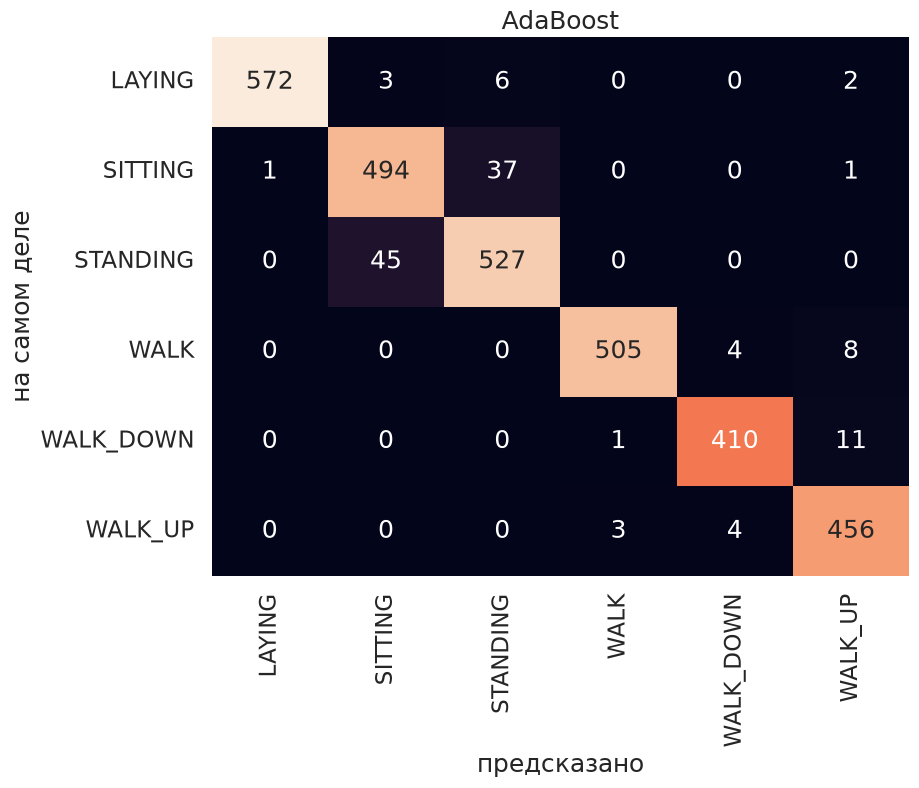

In [17]:
short = ['LAYING', 'SITTING', 'STANDING', 'WALK', 'WALK_DOWN', 'WALK_UP']

sns.set_context('talk')
cm = confusion_matrix(y_test, y_pred_abc)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, xticklabels=short, yticklabels=short, ax=ax)
ax.set(xlabel='предсказано', ylabel='на самом деле', title='AdaBoost');

**Ответ.**

Перебирались `n_estimators` = 100, 150, 200, `learning_rate` = 1.0, 0.1, 0.01 и глубина базового дерева 1, 2, 3. Лучшая модель: глубина 3, `learning_rate=0.1`, 200 деревьев, accuracy на кросс-валидации 0.956.

Больше всего влияет глубина дерева. С пнями (глубина 1) accuracy всего 0.51-0.64: у пня только два листа, а классов шесть, и из таких слабых моделей AdaBoost хорошую не собирает.

На test у AdaBoost accuracy 0.959 и 126 ошибок, у градиентного бустинга 0.992 и 26 ошибок. Путаница SITTING/STANDING выросла (82 ошибки), и, как и написано выше, появились ошибки в других классах: LAYING и разные виды ходьбы. Скорее всего, дело в том, что AdaBoost сильно увеличивает вес неправильно классифицированных объектов, и спорные примеры "сидит/стоит" начинают мешать остальным.

## Вопрос 6

* Постройте модель логистической регрессии с регуляризацией. Это может быть аналог модели, которая хорошо себя показала в упражнениях 4-й недели.
* Используя `VotingClassifier`, постройте модель логистической регрессии вместе с моделью GratientBoostedClassifier или AdaBoost (или обеими) из вопросов 4 и 5.
* Определите ошибку, как и ранее, и сравните результаты с соответствующими моделями с градиентным бустингом.
* Постройте матрицу путаницы для лучшей модели, созданной в этом наборе упражнений.

In [18]:
# логистическая регрессия с L2, как в лабе 5
t0 = time.time()
LR_L2 = LogisticRegressionCV(Cs=10, cv=4, l1_ratios=(0,), scoring='accuracy', use_legacy_attributes=False,
                             max_iter=1000, n_jobs=4).fit(X_train, y_train)
print(f'{time.time() - t0:.0f} с, выбранное C = {LR_L2.C_:.3f}')

49 с, выбранное C = 2.783


Проверьте ошибки и матрицу путаницы для модели логистической регрессии.

In [19]:
y_pred_lr = LR_L2.predict(X_test)
print(classification_report(y_test, y_pred_lr, target_names=le.classes_, digits=4))

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       583
           SITTING     0.9586    0.9550    0.9568       533
          STANDING     0.9599    0.9615    0.9607       572
           WALKING     0.9942    0.9981    0.9961       517
WALKING_DOWNSTAIRS     0.9976    0.9976    0.9976       422
  WALKING_UPSTAIRS     0.9978    0.9957    0.9968       463

          accuracy                         0.9838      3090
         macro avg     0.9847    0.9846    0.9847      3090
      weighted avg     0.9838    0.9838    0.9838      3090



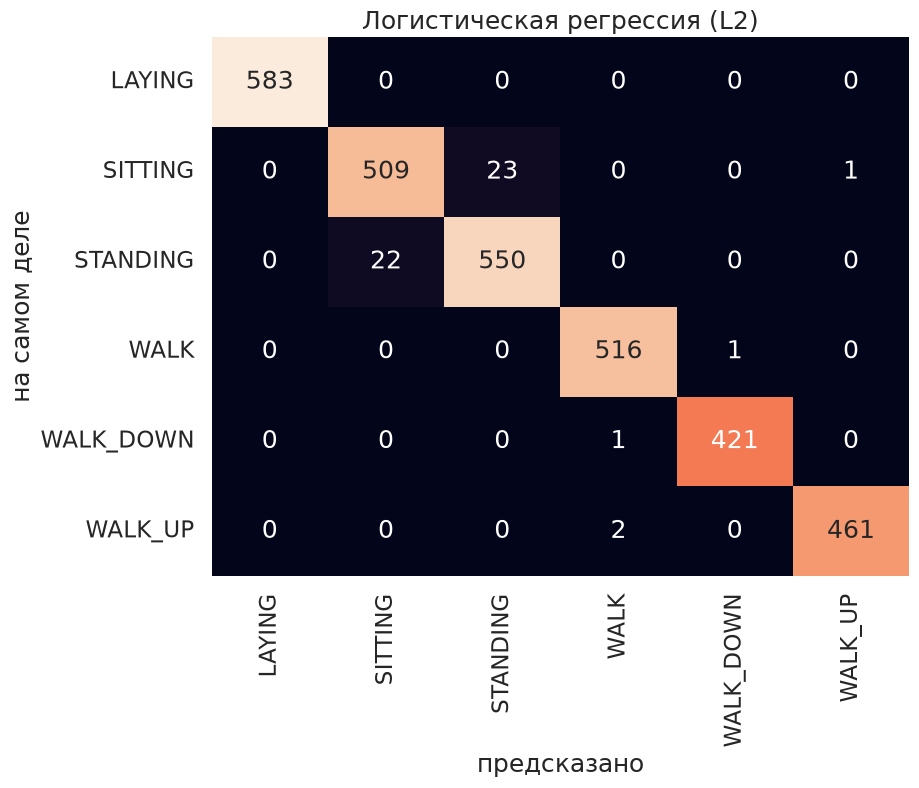

In [20]:
short = ['LAYING', 'SITTING', 'STANDING', 'WALK', 'WALK_DOWN', 'WALK_UP']

sns.set_context('talk')
cm = confusion_matrix(y_test, y_pred_lr)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, xticklabels=short, yticklabels=short, ax=ax)
ax.set(xlabel='предсказано', ylabel='на самом деле', title='Логистическая регрессия (L2)');

А теперь — многоуровневая модель (stacked model).

In [21]:
# голосование логистической регрессии и градиентного бустинга, soft - усредняются вероятности
lr_fixed = LogisticRegression(C=LR_L2.C_, max_iter=1000)   # C уже подобрано выше
estimators = [('LR_L2', lr_fixed), ('GBC', GV_GBC.best_estimator_)]

t0 = time.time()
VC = VotingClassifier(estimators, voting='soft')
VC = VC.fit(X_train, y_train)
print(f'VotingClassifier: {time.time() - t0:.0f} с')

VotingClassifier: 45 с


Наконец, рассмотрим ошибку классификатора при голосовании. Здесь мы показываем немного лучшие результаты, чем при использовании либо логистической регрессии, либо градиентных бустеров по отдельности. Однако тот факт, что логистическая регрессия демонстрирует почти такие же результаты, как и градиентные бустеры, служит важным напоминанием о том, что сначала следует пробовать самую простую модель. В некоторых случаях её эффективности будет вполне достаточно.

In [22]:
models_all = {'LogisticRegression': LR_L2, 'GradientBoosting': GV_GBC, 'AdaBoost': GV_ABC, 'Voting (LR + GB)': VC}
summary = {}
preds = {}
for name, model in models_all.items():
    preds[name] = model.predict(X_test)
    summary[name] = {'accuracy': accuracy_score(y_test, preds[name]),
                     'F1 (weighted)': f1_score(y_test, preds[name], average='weighted'),
                     'ошибок': (preds[name] != y_test).sum(),
                     'сидит/стоит': ((preds[name] == 1) & (y_test == 2)).sum() + ((preds[name] == 2) & (y_test == 1)).sum()}
summary = pd.DataFrame(summary).T
summary.round(4)

,accuracy,F1 (weighted),ошибок,сидит/стоит
LogisticRegression,0.9838,0.9838,50.0,45.0
GradientBoosting,0.9916,0.9916,26.0,21.0
AdaBoost,0.9592,0.9593,126.0,82.0
Voting (LR + GB),0.9900,0.9900,31.0,28.0


In [23]:
y_pred = VC.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       583
           SITTING     0.9719    0.9737    0.9728       533
          STANDING     0.9772    0.9738    0.9755       572
           WALKING     0.9981    0.9981    0.9981       517
WALKING_DOWNSTAIRS     0.9976    1.0000    0.9988       422
  WALKING_UPSTAIRS     0.9978    0.9978    0.9978       463

          accuracy                         0.9900      3090
         macro avg     0.9904    0.9906    0.9905      3090
      weighted avg     0.9900    0.9900    0.9900      3090



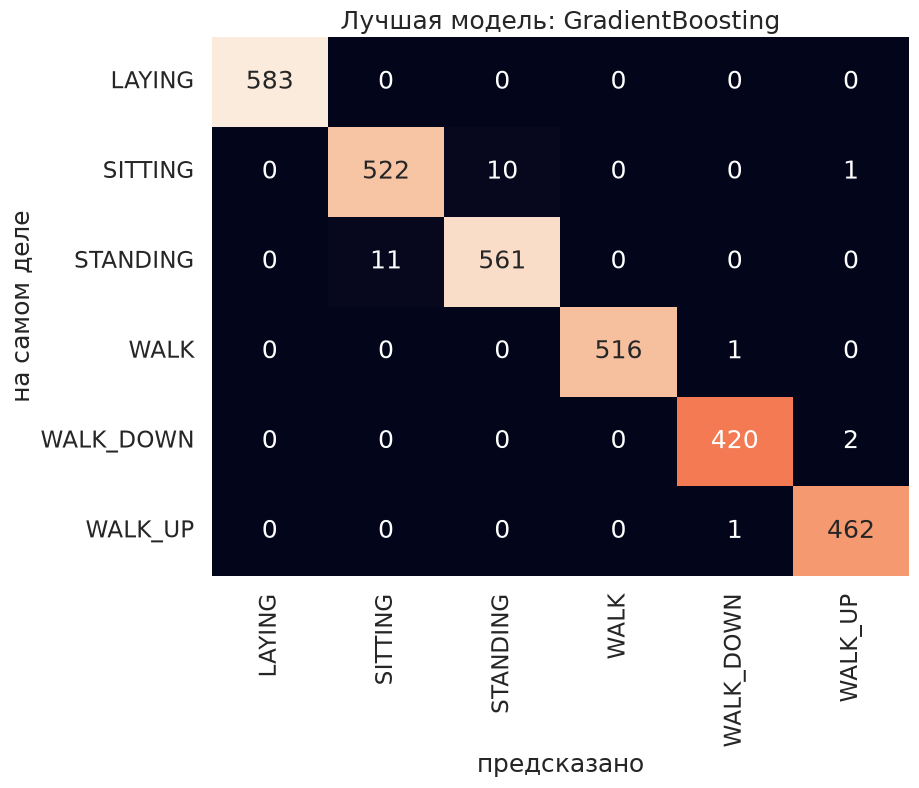

In [24]:
short = ['LAYING', 'SITTING', 'STANDING', 'WALK', 'WALK_DOWN', 'WALK_UP']

best_name = summary['accuracy'].idxmax()
sns.set_context('talk')
cm = confusion_matrix(y_test, preds[best_name])
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cbar=False, xticklabels=short, yticklabels=short, ax=ax)
ax.set(xlabel='предсказано', ylabel='на самом деле', title=f'Лучшая модель: {best_name}');

**Ответ.**

Логистическая регрессия с L2 (C = 2.78, как в лабе 5): accuracy 0.984, 50 ошибок, из них 45 - SITTING/STANDING.

VotingClassifier (логистическая регрессия + градиентный бустинг, soft) дал accuracy 0.990 и 31 ошибку. Это лучше логистической регрессии, но немного хуже одного градиентного бустинга (26 ошибок), так что здесь голосование не оказалось лучше каждой модели по отдельности. Скорее всего, потому что обе модели ошибаются на одних и тех же объектах (сидит/стоит), а логистическая регрессия на них слабее и немного портит прогноз бустинга.

При этом логистическая регрессия отстает от лучшей модели меньше чем на 1%, хотя она намного проще и быстрее. Так что начинать действительно лучше с простой модели.

Лучшая модель здесь - GradientBoosting, ее матрица ошибок выше.